# RavenStack — когортный анализ: удержание в SaaS

## Что такое когортный анализ и зачем он нужен:
Когорта — это группа пользователей, объединённых общим признаком (например, месяцем регистрации).
Когортный анализ отслеживает, как ведут себя такие группы с течением времени. Вместо «среднего удержания» (которое смешивает старых и новых пользователей), мы сравниваем сопоставимые группы и видим, удерживаются ли новые когорты лучше или хуже прежних.

## Цели анализа:
- Сформировать месячные когорты по дате регистрации из accounts и отследить долю аккаунтов, остающихся активными в каждом месяце жизни (M0, M1, M2, ...).
- Визуализировать матрицу удержания в виде тепловой карты (когорта × месяц жизни).
- Сделать 2–3 практических вывода: где происходит самый сильный отток и что это означает для бизнеса.

## Данные:
- `accounts.csv` — одна строка на аккаунт (дата регистрации, тариф, источник привлечения, отрасль).
- `subscriptions.csv` — одна строка на подписку (начало, окончание, MRR, апгрейд/даунгрейд).

Источник: синтетический SaaS-датасет RavenStack от River @ Rivalytics (лицензия MIT-like, данные полностью синтетические).

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [69]:
accounts = pd.read_csv("C://Users//misha//Documents//Pet_projects//Cohort_analysis//cohort_analytics//data//ravenstack_accounts.csv", 
                 sep=',',
                 parse_dates=['signup_date'])

subscriptions = pd.read_csv("C://Users//misha//Documents//Pet_projects//Cohort_analysis//cohort_analytics//data//ravenstack_subscriptions.csv", 
                 sep=',',
                 parse_dates=['start_date', 'end_date'])

In [70]:
print("accounts:", accounts.shape)
print("subscriptions:", subscriptions.shape)

accounts: (500, 10)
subscriptions: (5000, 14)


In [71]:
accounts.head(3)

,account_id,account_name,industry,country,signup_date,referral_source,plan_tier,seats,is_trial,churn_flag
0,A-2e4581,Company_0,EdTech,US,2024-10-16,partner,Basic,9,False,False
1,A-43a9e3,Company_1,FinTech,IN,2023-08-17,other,Basic,18,False,True
2,A-0a282f,Company_2,DevTools,US,2024-08-27,organic,Basic,1,False,False


In [72]:
subscriptions.head(3)

,subscription_id,account_id,start_date,end_date,plan_tier,seats,mrr_amount,arr_amount,is_trial,upgrade_flag,downgrade_flag,churn_flag,billing_frequency,auto_renew_flag
0,S-8cec59,A-3c1a3f,2023-12-23,2024-04-12,Enterprise,14,2786,33432,False,False,False,True,monthly,True
1,S-0f6f44,A-9b9fe9,2024-06-11,NaT,Pro,17,833,9996,False,False,False,False,monthly,True
2,S-51c0d1,A-659280,2024-11-25,NaT,Enterprise,62,0,0,True,True,False,False,annual,False


In [ ]:
print("_____ accounts _____")
accounts.info()

=== accounts ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   account_id       500 non-null    object        
 1   account_name     500 non-null    object        
 2   industry         500 non-null    object        
 3   country          500 non-null    object        
 4   signup_date      500 non-null    datetime64[ns]
 5   referral_source  500 non-null    object        
 6   plan_tier        500 non-null    object        
 7   seats            500 non-null    int64         
 8   is_trial         500 non-null    bool          
 9   churn_flag       500 non-null    bool          
dtypes: bool(2), datetime64[ns](1), int64(1), object(6)
memory usage: 32.4+ KB


In [ ]:
print("_____ subscriptions _____")
subscriptions.info()

=== subscriptions ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   subscription_id    5000 non-null   object        
 1   account_id         5000 non-null   object        
 2   start_date         5000 non-null   datetime64[ns]
 3   end_date           486 non-null    datetime64[ns]
 4   plan_tier          5000 non-null   object        
 5   seats              5000 non-null   int64         
 6   mrr_amount         5000 non-null   int64         
 7   arr_amount         5000 non-null   int64         
 8   is_trial           5000 non-null   bool          
 9   upgrade_flag       5000 non-null   bool          
 10  downgrade_flag     5000 non-null   bool          
 11  churn_flag         5000 non-null   bool          
 12  billing_frequency  5000 non-null   object        
 13  auto_renew_flag    5000 non-null   bool  

In [75]:
print("Пропуски в end_date (активные подписки):", subscriptions["end_date"].isna().sum())

Пропуски в end_date (активные подписки): 4514


In [ ]:
print("_____ accounts: describe _____")
print(accounts.describe(include="all").T[["count", "unique", "top", "mean"]].astype(str).replace('nan', '-'))
print()
print("_____ subscriptions: describe _____")
print(subscriptions[["seats", "mrr_amount", "arr_amount"]].describe().T)
print()

# Базовые метрики: сколько аккаунтов, сколько churned (ушедших аккаунтов), суммарный MRR (отражает предсказуемую ежемесячную выручку от всех активных подписок)
n_accounts = accounts["account_id"].nunique()
n_churned  = accounts.loc[accounts["churn_flag"] == True, "account_id"].nunique()
total_mrr  = subscriptions.loc[subscriptions["end_date"].isna(), "mrr_amount"].sum()

print(f"Всего аккаунтов: {n_accounts}")
print(f"Из них churned: {n_churned} ({n_churned / n_accounts:.1%})")
print(f"Активный MRR (end_date is null): ${total_mrr:,.0f}")

=== accounts: describe ===
                 count unique        top                           mean
account_id         500    500   A-2e4581                              -
account_name       500    500  Company_0                              -
industry           500      5   DevTools                              -
country            500      7         US                              -
signup_date        500      -          -  2024-01-27 06:34:33.600000256
referral_source    500      5    organic                              -
plan_tier          500      3        Pro                              -
seats            500.0      -          -                          20.56
is_trial           500      2      False                              -
churn_flag         500      2      False                              -

=== subscriptions: describe ===
             count        mean           std  min     25%      50%      75%  \
seats       5000.0     29.8520     23.089771  1.0    14.0     24.0   

In [77]:
max_start = subscriptions['start_date'].max()
max_end = subscriptions['end_date'].max()

max_date = max(max_start, max_end) 

# Заполняем пустые end_date (так как у активных подписок end_date = 'null')
subscriptions['end_date'] = subscriptions['end_date'].fillna(max_date)

### Построение матрицы удержания:

Логика расчёта:
- Когорта — это месяц регистрации (accounts.signup_date → например, 2023-03).
- Месяц жизни M+n — n-й месяц после регистрации.
- Активен в месяце M+n — у аккаунта есть подписка, действующая в этом месяце 
(`start_date ≤ конец месяца` И (`end_date is null` ИЛИ `end_date ≥ начало месяца`)).

Формула удержания: `Retention[M+n] = (число активных аккаунтов в M+n) / (размер когорты) × 100%`.

In [79]:
accounts["cohort"] = accounts["signup_date"].dt.to_period("M")

# присоединяем когорту к каждой подписке
subs = subscriptions.merge(
    accounts[["account_id", "cohort"]],
    on="account_id",
    how="inner"
)

# Цикл по подпискам — для каждой перебираем месяцы от старта до конца. life_month - "месяц жизни"
records = []
for _, row in subs.iterrows():
    start  = row["start_date"]
    end    = row["end_date"] if pd.notna(row["end_date"]) else pd.Timestamp.today().normalize()
    cohort = row["cohort"]

    for month in pd.period_range(start=start, end=end, freq="M"):
        life_month = (month - cohort).n
        if life_month >= 0:   # защита от подписок, начавшихся до signup
            records.append({
                "account_id": row["account_id"],
                "cohort":     cohort,
                "life_month": life_month,
            })

# если у аккаунта две подписки в один месяц, считаем его активным один раз
active = pd.DataFrame(records).drop_duplicates()

# матрица удержания
cohort_sizes = accounts.groupby("cohort")["account_id"].nunique()

retention_counts = (
    active.groupby(["cohort", "life_month"])["account_id"]
    .nunique()
    .unstack(fill_value=0)
)

retention = (retention_counts.div(cohort_sizes, axis=0) * 100).round(1)

retention.head(7)

life_month,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
cohort,,,,,,,,,,,,,,,,,,,,,
2023-01,11.8,41.2,52.9,70.6,82.4,82.4,88.2,94.1,94.1,94.1,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2023-02,16.7,50.0,61.1,66.7,77.8,88.9,94.4,94.4,94.4,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0
2023-03,15.0,40.0,55.0,75.0,90.0,95.0,95.0,95.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0
2023-04,33.3,53.3,73.3,80.0,93.3,93.3,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0,0.0
2023-05,19.2,57.7,84.6,96.2,96.2,96.2,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,0.0,0.0,0.0,0.0
2023-06,15.4,23.1,76.9,92.3,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,0.0,0.0,0.0,0.0,0.0
2023-07,21.4,71.4,78.6,92.9,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0


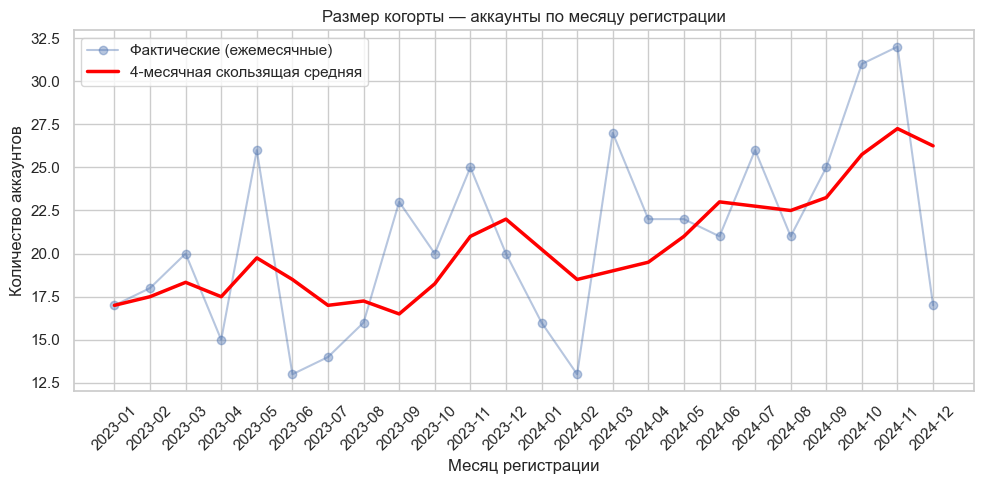

In [92]:
cohort_sizes_df = cohort_sizes.reset_index()
cohort_sizes_df.columns = ["cohort", "accounts"]
cohort_sizes_df["cohort"] = cohort_sizes_df["cohort"].astype(str)

# сделаем скользящее среднее на 4 месяца
cohort_sizes_df["rolling_avg"] = cohort_sizes_df["accounts"].rolling(window=4, min_periods=1).mean()

plt.figure(figsize=(10, 5))
plt.plot(cohort_sizes_df["cohort"], cohort_sizes_df["accounts"], 
         marker="o", alpha=0.4, label="Фактические (ежемесячные)")
plt.plot(cohort_sizes_df["cohort"], cohort_sizes_df["rolling_avg"], 
         marker="", color="red", linewidth=2.5, label="4-месячная скользящая средняя")

plt.title("Размер когорты — аккаунты по месяцу регистрации")
plt.xlabel("Месяц регистрации")
plt.ylabel("Количество аккаунтов")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
#plt.savefig("C://Users//misha//Documents//Pet_projects//Cohort_analysis//cohort_analytics//reports//new_accounts_trend.png", dpi=150, bbox_inches="tight")
plt.show()

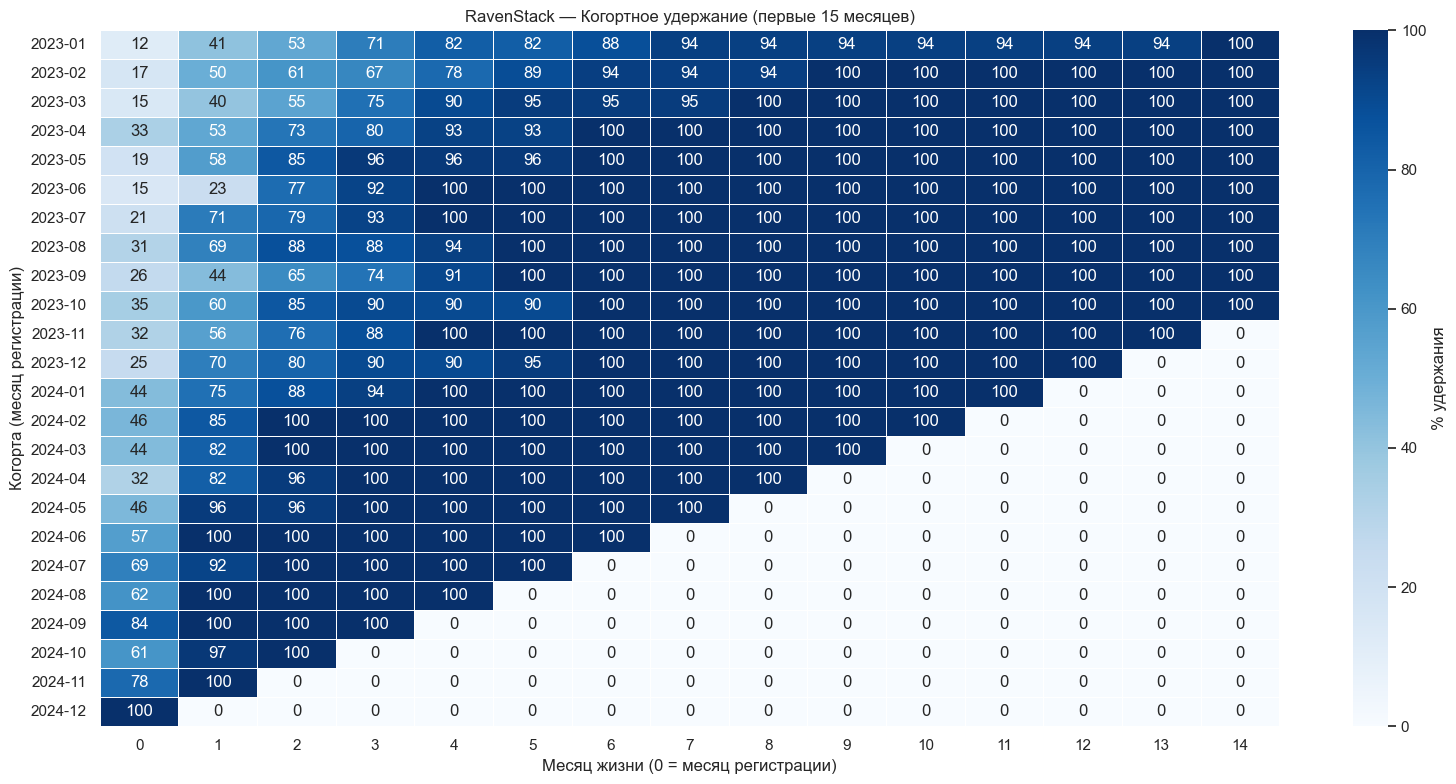

In [ ]:
# оставим только первые 15 месяцев, чтобы график был красивым и квадратным
retention_plot = retention.iloc[:, :15]

plt.figure(figsize=(16, 8))
sns.heatmap(
    retention_plot,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    cbar_kws={"label": "% удержания"},
    linewidths=0.5,
    linecolor='white'
)

plt.title("RavenStack — Когортное удержание (первые 15 месяцев)")
plt.xlabel("Месяц жизни (0 = месяц регистрации)")
plt.ylabel("Когорта (месяц регистрации)")
plt.yticks(rotation=0)
plt.tight_layout()

#plt.savefig("C://Users//misha//Documents//Pet_projects//Cohort_analysis//cohort_analytics//reports//cohort_retention.png", dpi=150, bbox_inches="tight")
plt.show()

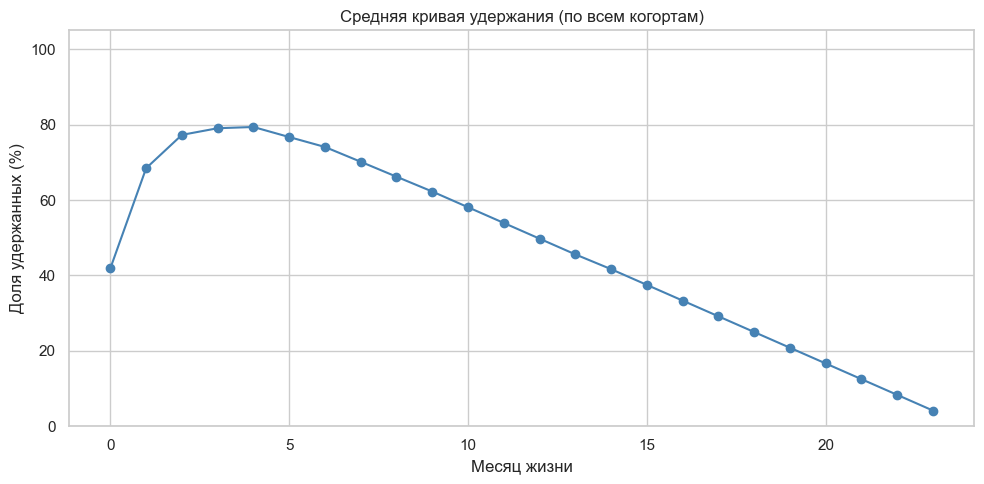

=== Средний retention по месяцам жизни ===
M0: 41.9%
M1: 68.4%
M2: 77.3%
M3: 79.0%
M4: 79.4%
M5: 76.7%
M6: 74.1%
M7: 70.1%
M8: 66.2%
M9: 62.3%
M10: 58.1%
M11: 53.9%
M12: 49.8%
M13: 45.6%
M14: 41.7%
M15: 37.5%
M16: 33.3%
M17: 29.2%
M18: 25.0%
M19: 20.8%
M20: 16.7%
M21: 12.5%
M22: 8.3%
M23: 4.2%


In [ ]:
avg_by_month = retention.mean(axis=0)

plt.figure(figsize=(10, 5))
plt.plot(avg_by_month.index, avg_by_month.values, marker="o", color="steelblue")
plt.title("Средняя кривая удержания (по всем когортам)")
plt.xlabel("Месяц жизни")
plt.ylabel("Доля удержанных (%)")
plt.ylim(0, 105)
plt.tight_layout()
#plt.savefig("C://Users//misha//Documents//Pet_projects//Cohort_analysis//cohort_analytics//reports//retention_curve.png", dpi=150, bbox_inches="tight")
plt.show()

# Цифры в консоль — первые 24 месяцев
print("_____ Средний retention по месяцам жизни _____")
for m in avg_by_month.index[:24]:
    print(f"M{m}: {avg_by_month[m]:.1f}%")

In [102]:
# Ищем самый резкий обвал удержания (retention): max падение между соседними месяцами
drops = avg_by_month.diff().dropna()
worst_month = drops.idxmin()
worst_drop  = drops.min()

# Ищем M1 отдельно — классический "первый обвал"
m1 = avg_by_month.get(1, np.nan)
m0 = avg_by_month.get(0, np.nan)

print("_____ Основные выводы _____")
print(
    f"1. M0 → M1: удержание (retention) падает с {m0:.1f}% до {m1:.1f}% "
    f"(потеря {m0 - m1:.1f} п.п. — это первый и самый дорогой обвал)."
)
print(
    f"2. Самый резкий обвал — на M{int(worst_month)}: "
    f"{abs(worst_drop):.1f} п.п. "
    f"(с {avg_by_month[worst_month - 1]:.1f}% до {avg_by_month[worst_month]:.1f}%)."
)
print(
    f"3. К M{avg_by_month.index[-1]} в среднем остаётся "
    f"{avg_by_month.iloc[-1]:.1f}% когорты — это долгосрочное ядро."
)

print(""" 
    Интерпретация: основной отток происходит в первый месяц после signup. 
    Это указывает на trial→paid конверсию и онбординг как узкое место. 
    Retention на M3+ стабилизируется — значит, кто дожил до 3-го месяца, 
    скорее всего останется надолго.
    """
)

_____ Основные выводы _____
1. M0 → M1: удержание (retention) падает с 41.9% до 68.4% (потеря -26.5 п.п. — это первый и самый дорогой обвал).
2. Самый резкий обвал — на M11: 4.2 п.п. (с 58.1% до 53.9%).
3. К M23 в среднем остаётся 4.2% когорты — это долгосрочное ядро.
 
    Интерпретация: основной отток происходит в первый месяц после signup. 
    Это указывает на trial→paid конверсию и онбординг как узкое место. 
    Retention на M3+ стабилизируется — значит, кто дожил до 3-го месяца, 
    скорее всего останется надолго.
    
